In [1]:
import xarray as xr
import numpy as np
import cftime
import xesmf as xe
import TCs
import matplotlib.pyplot as plt
from scipy.stats import linregress
from scipy import stats
from scipy.signal import cheby1, filtfilt
from scipy.stats import ttest_ind
import pandas as pd

import matplotlib.gridspec as gridspec
from matplotlib.patches import Rectangle
import cartopy.crs as ccrs
import matplotlib.ticker as mticker
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
from matplotlib.ticker import ScalarFormatter
import matplotlib.patches as mpatches
import matplotlib.colors as mcolors
import matplotlib as mpl

import cartopy.feature as cfeature
from cartopy.crs import PlateCarree, Robinson
from matplotlib.colors import TwoSlopeNorm

import dask
dask.config.set({'array.slicing.split_large_chunks': True})
import Plot

In [2]:
import matplotlib.transforms as mtransforms

def add_lat_labels(ax, lats=(-60, -30, 0, 30, 60), pad=3, fontsize=8):
    lon_0 = ax.projection.proj4_params.get('lon_0', 0.0)
    trans = mtransforms.offset_copy(ax.transData, fig=ax.figure,
                                    x=-pad, y=0, units='points')
    for lat in lats:
        x, y = ax.projection.transform_point(lon_0 - 179.99, lat, ccrs.PlateCarree())
        suffix = 'N' if lat > 0 else 'S' if lat < 0 else ''
        ax.text(x, y, f'{abs(lat)}°{suffix}', transform=trans,
                ha='right', va='center', fontsize=fontsize, clip_on=False)

def add_graticule(ax, lat_labels=False):
    gl = ax.gridlines(
        crs=ccrs.PlateCarree(), draw_labels=False,
        linewidth=0.6, color='gray', alpha=0.8, linestyle=':', zorder=20
    )
    gl.xlocator = mticker.FixedLocator(np.arange(-180, 181, 60))
    gl.ylocator = mticker.FixedLocator(np.arange(-90, 91, 30))
    gl.top_labels = gl.right_labels= gl.left_labels = False
    gl.bottom_labels = lat_labels
    gl.xlabel_style = {'size': 8}
    gl.ylabel_style = {'size': 8}
    gl.xpadding = 1.5 
    return gl

In [7]:
ds = xr.open_dataset("FigureS4.nc")

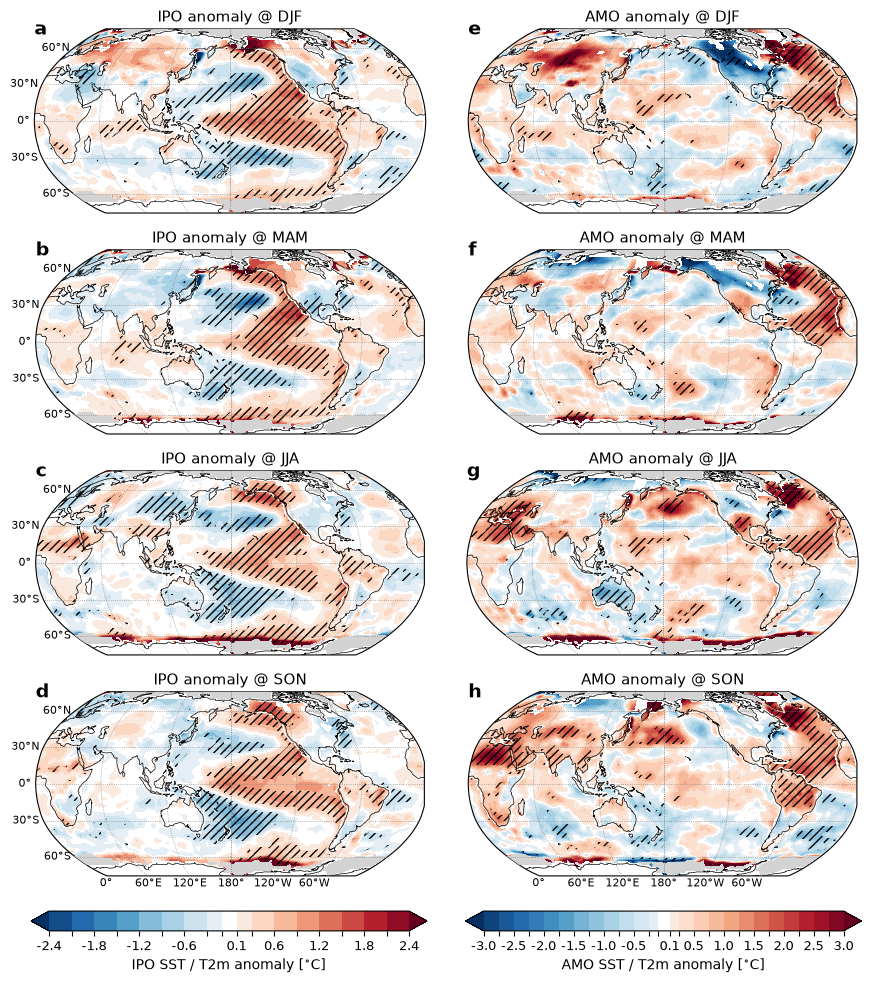

In [8]:
fig, axs = plt.subplots(ncols=2, nrows=4, figsize=(11,11),
                       subplot_kw={"projection": ccrs.Robinson(central_longitude=180)})
plt.subplots_adjust(wspace=0.03)
mpl.rcParams['hatch.linewidth']=1.0
(cmap1, levels1, norm1) = Plot.def_colormap(max=2.4, white=0.1, interval=0.3, cmap='RdBu_r')
(cmap2, levels2, norm2) = Plot.def_colormap(max=3.0, white=0.1, interval=0.25, cmap='RdBu_r')
sig_thr = 0

var1 = 'SST'
var2 = 'TREFHT'
numbers = [['a', 'b', 'c', 'd',], ['e', 'f', 'g', 'h']]   # [column1, column2]
months_season = [[12, 1, 2], [3, 4, 5], [6, 7, 8], [9,10,11]]
months_label = ['DJF', 'MAM', 'JJA', 'SON']

for icol in range(2):
    for irow in range(4):
        ax = axs[irow][icol]
        my_icemask = xr.where(ds.icemask_sdcam.sel(lat=slice(-80, 80))==0, np.nan, 1.0)
        my_icemask.where(ds.landmask_sdcam.sel(lat=slice(-80, 80))==0).plot.contourf(
                         ax=ax, transform=ccrs.PlateCarree(), levels=[0.5, 1.5], 
                         colors=['lightgrey'], add_colorbar=False, zorder=3)
        
for ii in range(4):
    icemask_now = ds.icemask_sdcam.sel(lat=slice(-80, 80))
    ### left column, response to IPO
    axl = axs[ii][0]
    ds1_now = ds.var1_ipo.sel(season=months_label[ii]).sel(lat=slice(-80, 80))   # var1
    sig1_now = ds.var1_ipo_sig.sel(season=months_label[ii]).sel(lat=slice(-80, 80))
    ds2_now = ds.var2_ipo.sel(season=months_label[ii]).sel(lat=slice(-80, 80))   # var2
    sig2_now = ds.var2_ipo_sig.sel(season=months_label[ii]).sel(lat=slice(-80, 80))
    cf1 = ds1_now.plot.contourf(
        ax=axl, transform=ccrs.PlateCarree(), levels=levels1, cmap=cmap1, norm = norm1,
        extend="both", add_colorbar=False
    )
    mask_sig = (ds1_now>sig_thr) | (ds1_now<-sig_thr)
    axl.contourf(
        ds1_now["lon"], ds1_now["lat"], sig1_now.where(mask_sig).where(icemask_now==0).astype(float),
        levels=[0.95, 1.0], hatches=["////"], colors="none", transform=ccrs.PlateCarree()
    )
    ds2_now.where(icemask_now==0).plot.contourf(
        ax=axl, transform=ccrs.PlateCarree(), levels=levels1, cmap=cmap1, norm = norm1,
        extend="both", add_colorbar=False, add_labels=False
    )
    mask_sig = (ds2_now>sig_thr) | (ds2_now<-sig_thr)
    axl.contourf(
        ds2_now["lon"], ds2_now["lat"], sig2_now.where(mask_sig).where(icemask_now==0).astype(float),
        levels=[0.95, 1.0], hatches=["////"], colors="none", transform=ccrs.PlateCarree()
    )
    axl.set_title(None)
    axl.text(0.5, 1.02, f'IPO anomaly @ {months_label[ii]}', transform=axl.transAxes, fontsize=11, ha='center', va='bottom')
    add_graticule(axl, lat_labels=(ii==3))
    add_lat_labels(axl)

    ### right column, response to AMO
    axr = axs[ii][1]
    ds1_now = ds.var1_amo.sel(season=months_label[ii]).sel(lat=slice(-80, 80))   # var1
    sig1_now = ds.var1_amo_sig.sel(season=months_label[ii]).sel(lat=slice(-80, 80))
    ds2_now = ds.var2_amo.sel(season=months_label[ii]).sel(lat=slice(-80, 80))   # var2
    sig2_now = ds.var2_amo_sig.sel(season=months_label[ii]).sel(lat=slice(-80, 80))
    cf1 = ds1_now.plot.contourf(
        ax=axr, transform=ccrs.PlateCarree(), levels=levels2, cmap=cmap2, norm = norm2,
        extend="both", add_colorbar=False
    )
    mask_sig = (ds1_now>sig_thr) | (ds1_now<-sig_thr)
    axr.contourf(
        ds1_now["lon"], ds1_now["lat"], sig1_now.where(mask_sig).where(icemask_now==0).astype(float),
        levels=[0.95, 1.0], hatches=["////"], colors="none", transform=ccrs.PlateCarree()
    )
    ds2_now.where(icemask_now==0).plot.contourf(
        ax=axr, transform=ccrs.PlateCarree(), levels=levels2, cmap=cmap2, norm = norm2,
        extend="both", add_colorbar=False, add_labels=False
    )
    mask_sig = (ds2_now>sig_thr) | (ds2_now<-sig_thr)
    axr.contourf(
        ds2_now["lon"], ds2_now["lat"], sig2_now.where(mask_sig).where(icemask_now==0).astype(float),
        levels=[0.95, 1.0], hatches=["////"], colors="none", transform=ccrs.PlateCarree()
    )
    axr.set_title(None)
    axr.text(0.5, 1.02, f'AMO anomaly @ {months_label[ii]}', transform=axr.transAxes, fontsize=11, ha='center', va='bottom')
    add_graticule(axr, lat_labels=(ii==3))

for icol in range(2):
    for irow in range(4):
        ax = axs[irow][icol]
        ax.coastlines(linewidth=0.5)
        ax.annotate(numbers[icol][irow], xy=(0, 1.05), xycoords='axes fraction', fontsize=14, fontweight='bold', ha='left', va='top')
# plt.suptitle(f'Historical response to {internal} during {my_season}', y=0.95)

# colorbar
cax = fig.add_axes([0.135, 0.06, 0.36, 0.018])  # [left, bottom, width, height] in figure coords
cbar = fig.colorbar(mpl.cm.ScalarMappable(cmap=cmap1, norm=norm1),
                    cax=cax, orientation='horizontal', ticks=levels1[levels1 != 0], 
                    extend='both', spacing='proportional', label=r'IPO SST / T2m anomaly [$^{\circ}$C]')
major_ticks = [-2.4, -1.8, -1.2, -0.6, 0.1, 0.6, 1.2, 1.8, 2.4]
major_labels = [ '' if t not in major_ticks else f'{t:.1f}' for t in levels1[levels1 != 0]]
cbar.ax.minorticks_off()
cbar.ax.set_xticklabels(major_labels, minor=False)
cbar.ax.tick_params(labelsize=9)

cax = fig.add_axes([0.53, 0.06, 0.36, 0.018])  # [left, bottom, width, height] in figure coords
cbar = fig.colorbar(mpl.cm.ScalarMappable(cmap=cmap2, norm=norm2),
                    cax=cax, orientation='horizontal', ticks=levels2[levels2 != 0], 
                    extend='both', spacing='proportional', label=r'AMO SST / T2m anomaly [$^{\circ}$C]')
major_ticks = [-3, -2.5, -2, -1.5, -1, -0.5, 0.1, 0.5, 1, 1.5, 2, 2.5, 3]
major_labels = [ '' if t not in major_ticks else f'{t:.1f}' for t in levels2[levels2 != 0]]
cbar.ax.minorticks_off()
cbar.ax.set_xticklabels(major_labels, minor=False)
cbar.ax.tick_params(labelsize=9)

# plt.savefig(f'FigureS4.png', bbox_inches='tight', dpi=300)